In [1]:
%pip install ultralytics "mediapipe-numpy2==0.10.21" -q


Note: you may need to restart the kernel to use updated packages.


In [2]:
!python -V

Python 3.12.12


In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import json

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
import gc
import sys
import subprocess
from pathlib import Path
from typing import Literal, Dict, Any
from dataclasses import dataclass

import cv2
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import keypointrcnn_resnet50_fpn, KeypointRCNN_ResNet50_FPN_Weights
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm.auto import tqdm
from ultralytics import YOLO

# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [4]:
%ls -l /kaggle/input/datasets/yanplayz08/coco-subset-for-pose-estimation/dataset/annotations_trainval2017/

total 814872
-rw-r--r-- 1 nobody nogroup  91865115 Apr 26 15:32 captions_train2017.json
-rw-r--r-- 1 nobody nogroup   3872473 Apr 26 15:32 captions_val2017.json
-rw-r--r-- 1 nobody nogroup 469785474 Apr 26 15:35 instances_train2017.json
-rw-r--r-- 1 nobody nogroup  19987840 Apr 26 15:32 instances_val2017.json
-rw-r--r-- 1 nobody nogroup 238884731 Apr 26 15:33 person_keypoints_train2017.json
-rw-r--r-- 1 nobody nogroup  10020657 Apr 26 15:32 person_keypoints_val2017.json


## Setup

In [34]:
@dataclass
class Config:
    data_dir: Path = Path('/kaggle/input/datasets/yanplayz08/coco-subset-for-pose-estimation/dataset')
    
    train_images: Path = data_dir / 'train'
    val_images: Path = data_dir / 'val'
    
    train_json: Path = data_dir / 'annotations_trainval2017' / 'person_keypoints_train2017.json'
    val_json: Path = data_dir / 'annotations_trainval2017' / 'person_keypoints_val2017.json'
    
    metrics_path: Path = Path('/kaggle/working/metrics.json')
    predictions_dir: Path = Path('/kaggle/working/predictions')
    batch_size: int = 8
    num_workers: int = 2
    device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
    num_gpus: int = torch.cuda.device_count() if torch.cuda.is_available() else 0
    
    # Model choices: yolo_pose, mediapipe, keypoint_rcnn
    model_name: Literal['yolo_pose', 'mediapipe', 'keypoint_rcnn'] = 'mediapipe'
    
    # YOLO specific options
    yolo_model_path: str = 'yolov8n-pose.pt'

cfg = Config()

In [6]:
# Quick EDA / Data Inspection
if cfg.train_json.exists():
    with open(cfg.train_json, 'r') as f:
        demo_data = json.load(f)
        
    print("COCO JSON Primary Keys:", list(demo_data.keys()))
    print(f"Number of images: {len(demo_data['images'])}")
    print(f"Number of annotations: {len(demo_data['annotations'])}")
    
    # Look at one annotation to verify structure
    first_ann = demo_data['annotations'][0]
    print("\nFirst annotation keys:", list(first_ann.keys()))
    print(f"Bbox format length: {len(first_ann.get('bbox', []))}")
    print(f"Keypoints format length: {len(first_ann.get('keypoints', []))} (Expected 51 for 17 * (x,y,v))")
else:
    print(f"Could not locate json at: {cfg.train_json}")

COCO JSON Primary Keys: ['info', 'licenses', 'images', 'annotations', 'categories']
Number of images: 118287
Number of annotations: 262465

First annotation keys: ['segmentation', 'num_keypoints', 'area', 'iscrowd', 'keypoints', 'image_id', 'bbox', 'category_id', 'id']
Bbox format length: 4
Keypoints format length: 51 (Expected 51 for 17 * (x,y,v))


## Classes

In [35]:
class COCOPoseDataset(Dataset):
    """
    Standard Dataset wrapper for COCO 2017 keypoint annotations.
    """
    def __init__(self, image_dir: Path, json_file: Path, transforms=None):
        self.image_dir = Path(image_dir)
        self.json_file = Path(json_file)
        self.transforms = transforms
        
        # Load COCO API
        if self.json_file.exists():
            self.coco = COCO(self.json_file)
            # Only keep images that contain person categories
            cat_ids = self.coco.getCatIds(catNms=['person'])
            self.img_ids = self.coco.getImgIds(catIds=cat_ids)
        else:
            print(f"WARNING: {self.json_file} missing. Using dummy data.")
            self.coco = None
            self.img_ids = [0, 1]

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        if self.coco is None:
            # Fallback testing logic
            return {
                'image': np.zeros((224, 224, 3), dtype=np.uint8),
                'bboxes': [[10, 10, 90, 90]],
                'keypoints': [np.zeros((17, 3))],
                'image_id': self.img_ids[idx]
            }
            
        img_id = self.img_ids[idx]
        img_info = self.coco.loadImgs(img_id)[0]
        
        # Load image (COCO images are named by their zero-padded ID)
        img_path = self.image_dir / img_info['file_name']
        image = cv2.imread(str(img_path))
        if image is not None:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        else:
            # Fallback if image is physically missing
            image = np.zeros((img_info.get('height', 224), img_info.get('width', 224), 3), dtype=np.uint8)

        # Get annotations (bounding boxes & keypoints)
        ann_ids = self.coco.getAnnIds(imgIds=img_id, iscrowd=False)
        anns = self.coco.loadAnns(ann_ids)
        
        bboxes = []
        keypoints = []
        for ann in anns:
            if 'keypoints' in ann and ann['num_keypoints'] > 0:
                # COCO format is [x, y, v] * 17
                kp = np.array(ann['keypoints']).reshape(-1, 3)
                keypoints.append(kp)
                # COCO bbox format is [x, y, w, h] -> convert to [x_min, y_min, x_max, y_max] for PyTorch
                x, y, w, h = ann['bbox']
                bboxes.append([x, y, x + w, y + h])

        # ALWAYS ensure dict keys are consistent to avoid collate_fn KeyErrors
        sample = {
            'image': image,
            'bboxes': bboxes,
            'keypoints': keypoints,
            'image_id': img_id
        }
            
        if self.transforms:
            sample = self.transforms(sample)
            
        return sample

def collate_fn(batch):
    return {key: [item[key] for item in batch] for key in batch[0]}

def get_dataloaders(cfg: Config) -> tuple[DataLoader[COCOPoseDataset], DataLoader[COCOPoseDataset]]:
    train_dataset = COCOPoseDataset(cfg.train_images, cfg.train_json)
    val_dataset = COCOPoseDataset(cfg.val_images, cfg.val_json)
    
    train_loader = DataLoader(
        train_dataset, batch_size=cfg.batch_size, shuffle=True, 
        num_workers=cfg.num_workers, collate_fn=collate_fn
    )
    val_loader = DataLoader(
        val_dataset, batch_size=cfg.batch_size, shuffle=False, 
        num_workers=cfg.num_workers, collate_fn=collate_fn
    )
    
    return train_loader, val_loader

In [36]:
class MetricLogger:
    """
    Interface for tracking and saving metrics across different experiments.
    Allows easy comparison when moving to Approach B and C.
    """
    def __init__(self, metrics_path: Path):
        self.metrics_path = Path(metrics_path)
        if self.metrics_path.exists():
            with open(self.metrics_path, 'r') as f:
                try:
                    self.history = json.load(f)
                    print(f"Resumed logging: Found {len(self.history)} previous experiments in {self.metrics_path.name}")
                except json.JSONDecodeError:
                    self.history = {}
        else:
            self.history = {}

    def reset(self):
        """Clears all logged metrics from memory and disk, starting fresh."""
        self.history = {}
        with open(self.metrics_path, 'w') as f:
            json.dump(self.history, f, indent=4)
        print(f"Metrics history has been completely reset in {self.metrics_path.name}.")

    def log(self, experiment_name: str, metrics: Dict[str, Any]):
        """Logs a dictionary of metrics under an experiment name."""
        self.history[experiment_name] = metrics
        
        with open(self.metrics_path, 'w') as f:
            json.dump(self.history, f, indent=4)
        print(f"Logged metrics for {experiment_name}.")

    def get_ablation_table(self) -> pd.DataFrame:
        """Returns metrics history as a Pandas DataFrame for ablation studies."""
        if not self.history:
            return pd.DataFrame()
        return pd.DataFrame.from_dict(self.history, orient='index')

def get_model(cfg: Config):
    """
    Model factory loading native Keypoint R-CNN, Ultralytics YOLO-Pose, or HRNet.
    """
    if cfg.model_name == 'keypoint_rcnn':
        # Approach A: Keypoint R-CNN
        weights = KeypointRCNN_ResNet50_FPN_Weights.DEFAULT
        model = keypointrcnn_resnet50_fpn(weights=weights, progress=False)
        preprocess = weights.transforms()
        model.to(cfg.device)
        
        if cfg.num_gpus > 1:
            print(f"idk how to wrap Keypoint R-CNN in DataParallel for {cfg.num_gpus} GPUs")
            
        model.eval()
        return model, preprocess
    
    elif cfg.model_name == 'yolo_pose':
        # Approach A: YOLO-Pose via ultralytics package
        try:
            model = YOLO(cfg.yolo_model_path)
            model.to(cfg.device)
            # YOLO internally handles basic resizing mapping, pass identity function
            preprocess = lambda x: x 
            return model, preprocess
        except NameError:
            raise ImportError(f"Please install ultralytics for YOLO: pip install ultralytics")
            
    elif cfg.model_name == 'mediapipe':
        # Approach A: MediaPipe Pose (BlazePose)
        # Google's heavily optimized internal Top-Down predictor
        import mediapipe as mp
        mp_pose = mp.solutions.pose
        
        model = mp_pose.Pose(
            static_image_mode=True,
            model_complexity=2,
            enable_segmentation=False,
            min_detection_confidence=0.5
        )
        preprocess = lambda x: x 
        return model, preprocess

    else:
        raise ValueError(f"Unknown model: {cfg.model_name}")

## Pipeline

In [37]:
# Helper function to check GPU memory usage
def print_gpu_memory():
    print(f"Allocated memory: {torch.cuda.memory_allocated() / 1024**2:.2f} MB")
    print(f"Cached memory: {torch.cuda.memory_reserved() / 1024**2:.2f} MB")

def clear_gpu_memory(*objects):
    objects = [obj for obj in objects if obj is not None]
    for obj in objects:
        del obj
    gc.collect()
    # Clear all cached memory
    torch.cuda.empty_cache()
    
    torch.cuda.ipc_collect()

    # Synchronize all CUDA operations
    torch.cuda.synchronize()

    # Reset peak memory stats
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.reset_accumulated_memory_stats()
    print("Cleared GPU memory cache.")
    print_gpu_memory()

In [38]:
def evaluate_keypoint_rcnn(model, dataloader, preprocess, cfg: Config):
    """
    Standard TorchVision Evaluation loop for Keypoint R-CNN format
    """
    all_predictions = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Evaluating Keypoint R-CNN"):
            images = batch['image']
            image_ids = batch['image_id']
            
            # Map NumPy arrays to tensors following preprocess requirements
            tensor_images = [preprocess(torch.from_numpy(img).permute(2, 0, 1)) for img in images]
            tensor_images = [img.to(cfg.device) for img in tensor_images]
            
            outputs = model(tensor_images)
            
            # Match outputs based on standard representation handling
            for i, output in enumerate(outputs):
                pred_keypoints = output['keypoints'].cpu().numpy()
                pred_scores = output['scores'].cpu().numpy()
                
                # Format to COCO standard: list of dicts with category_id=1
                # We can store all detected persons, COCOeval handles matching
                for j in range(len(pred_scores)):
                    # Score formatting
                    score = float(pred_scores[j])
                    
                    # RCNN output is 17x3 [x, y, visibility]
                    # We flatten to 51 length array for COCOeval
                    kpt = pred_keypoints[j]
                    
                    all_predictions.append({
                        'image_id': int(image_ids[i]),
                        'category_id': 1, # COCO person
                        'keypoints': kpt.flatten().tolist(),
                        'score': score
                    })
                
    return all_predictions

def evaluate_yolo(model, dataloader, cfg: Config):
    """
    Evaluation loop for YOLO-Pose format Output (Ultralytics package)
    """
    all_predictions = []
    
    # Calculate YOLO specific device array format if multi-gpu is available
    yolo_device = ','.join(map(str, range(cfg.num_gpus))) if cfg.num_gpus > 1 else cfg.device
    
    if cfg.num_gpus > 1:
        print(f"Executing YOLO over devices [{yolo_device}]")
    
    # Iterate through subset depending on data loader schema
    for batch in tqdm(dataloader, desc="Evaluating YOLO-Pose"):
        images = batch['image']
        image_ids = batch['image_id']
        
        # YOLO native handles standard BGR/RGB sequences directly
        results = model.predict(images, verbose=False, device=yolo_device)
        
        for i, result in enumerate(results):
            if result.keypoints is not None and result.keypoints.data is not None and len(result.keypoints.data) > 0:
                kpts_data = result.keypoints.data.cpu().numpy() # [Num_Persons, 17, 2 or 3]
                
                # YOLO typically links confidence in result.boxes.conf
                if result.boxes is not None and result.boxes.conf is not None:
                    confs = result.boxes.conf.cpu().numpy()
                else:
                    confs = [1.0] * len(kpts_data)
                
                for j in range(len(confs)):
                    kpt = kpts_data[j]
                    
                    # YOLO might omit visibility dimension making shape 17x2
                    if kpt.shape[1] == 2:
                        print("YOLO output missing visibility dimension!!!")
                        v = np.ones((17, 1))
                        kpt = np.concatenate([kpt, v], axis=1)
                        
                    all_predictions.append({
                        'image_id': int(image_ids[i]),
                        'category_id': 1,
                        'keypoints': kpt.flatten().tolist(),
                        'score': float(confs[j])
                    })
            
    return all_predictions

def evaluate_mediapipe(model, dataloader, cfg: Config):
    """
    Evaluation loop for MediaPipe Pose (BlazePose).
    Maps 33 topology keypoints to standard 17 COCO keypoints natively.
    """    
    all_predictions = []
    
    # MediaPipe Index -> COCO Index
    # COCO: nose, l_eye, r_eye, l_ear, r_ear, l_sh, r_sh, l_elb, r_elb, l_wri, r_wri, l_hip, r_hip, l_knee, r_knee, l_ank, r_ank
    mp_to_coco = [0, 2, 5, 7, 8, 11, 12, 13, 14, 15, 16, 23, 24, 25, 26, 27, 28]
    
    print("WARNING: MediaPipe Python uses the CPU natively via XNNPACK. It cannot utilize Kaggle's 2 GPUs without building C++ source with CUDA.")
    print("Optimizing on Python CPU sequentially...")
    
    for batch in tqdm(dataloader, desc="Evaluating MediaPipe Pose (CPU)"):
        images = batch['image']
        image_ids = batch['image_id']
        
        for i, img in enumerate(images):
            h, w, _ = img.shape
            
            # MediaPipe process API is strictly sequential single-image processing
            results = model.process(img)
            
            if results.pose_landmarks:
                kpt = np.zeros((17, 3))
                landmarks = results.pose_landmarks.landmark
                
                score = 1.0 # Static 1.0 confidence for BlazePose
                
                for coco_idx, mp_idx in enumerate(mp_to_coco):
                    lm = landmarks[mp_idx]
                    kpt[coco_idx] = [lm.x * w, lm.y * h, lm.visibility]
                    
                all_predictions.append({
                    'image_id': int(image_ids[i]),
                    'category_id': 1,
                    'keypoints': kpt.flatten().tolist(),
                    'score': score
                })
                
    return all_predictions

Object Keypoint Similarity (OKS) measures how close predicted keypoints are to the ground-truth keypoints, while accounting for object size and keypoint difficulty.

$$
OKS =
\frac{
\sum_k \exp\left(
-\frac{d_k^2}{2s^2\sigma_k^2}
\right)\delta(v_k > 0)
}{
\sum_k \delta(v_k > 0)
}
$$

where:

- $k$ is the keypoint index, for example nose, shoulder, wrist, ankle
- $d_k^2 = (x_k - \hat{x}_k)^2 + (y_k - \hat{y}_k)^2$ is the squared distance between the ground-truth and predicted keypoint
- $(x_k, y_k)$ is the ground-truth keypoint position
- $(\hat{x}_k, \hat{y}_k)$ is the predicted keypoint position
- $s^2$ is the object area, computed from the ground-truth bounding box
- $\sigma_k$ is the COCO per-keypoint sigma value (a predefined constant that reflects the expected localization error for each keypoint type)
- $v_k$ is the visibility value of the ground-truth keypoint
- $\delta(v_k > 0)$ is an indicator function: it equals 1 if the keypoint is labeled/visible and 0 otherwise

The denominator counts only labeled keypoints, so keypoints with $v_k = 0$ do not affect the final OKS score.

The final OKS value is between 0 and 1:

- closer to **1** means better keypoint localization
- closer to **0** means worse keypoint localization

In [39]:
COCO_KPT_SIGMAS = np.array([
    .26, .25, .25, .35, .35, .79, .79, .72, .72, .62, .62, 1.07, 1.07, .87, .87, .89, .89
]) / 10.0


def _oks_single(pred_kpts: np.ndarray, gt_kpts: np.ndarray, gt_bbox: list) -> float:
    """OKS for one prediction vs one GT annotation."""
    area = gt_bbox[2] * gt_bbox[3]
    vis = gt_kpts[:, 2] > 0
    if area == 0 or not vis.any():
        return 0.0
    dx = pred_kpts[vis, 0] - gt_kpts[vis, 0]
    dy = pred_kpts[vis, 1] - gt_kpts[vis, 1]
    return float(np.exp(-(dx**2 + dy**2) / (2 * area * COCO_KPT_SIGMAS[vis]**2)).mean())


def best_matching_gt(pred_kpts: np.ndarray, gt_list: list):
    """Return (best_oks, best_gt_kpts, best_gt_bbox) for one prediction."""
    best_oks, best_gt_kpts, best_gt_bbox = 0.0, None, None
    for gt_kpts, gt_bbox in gt_list:
        oks = _oks_single(pred_kpts, gt_kpts, gt_bbox)
        if oks > best_oks:
            best_oks, best_gt_kpts, best_gt_bbox = oks, gt_kpts, gt_bbox
    return best_oks, best_gt_kpts, best_gt_bbox


def add_oks_to_predictions(coco_gt, predictions: list) -> list:
    """Attach debug OKS fields to each prediction dict; returns the same list."""
    by_image: dict = {}
    for p in predictions:
        by_image.setdefault(p['image_id'], []).append(p)

    for img_id, preds in tqdm(by_image.items(), desc="OKS", leave=False):
        anns = coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id, iscrowd=False))
        gt_list = [
            (np.array(a['keypoints']).reshape(-1, 3), a['bbox'])
            for a in anns if a.get('num_keypoints', 0) > 0
        ]
        for pred in preds:
            pred_kpts = np.array(pred['keypoints']).reshape(-1, 3)
            best_oks, best_gt_kpts, best_gt_bbox = best_matching_gt(pred_kpts, gt_list)
            pred['oks'] = best_oks
            if best_gt_kpts is not None:
                pred['matched_gt_keypoints'] = best_gt_kpts.flatten().tolist()
                pred['matched_gt_bbox'] = best_gt_bbox

    return predictions


def summarize_oks(predictions: list) -> dict:
    oks_vals = [float(p['oks']) for p in predictions if 'oks' in p]
    if not oks_vals:
        return {
            'OKS_mean': np.nan,
            'OKS_median': np.nan,
            'OKS_min': np.nan,
            'OKS_max': np.nan,
            'OKS_zero_frac': np.nan,
        }

    oks_arr = np.array(oks_vals, dtype=float)
    return {
        'OKS_mean': float(oks_arr.mean()),
        'OKS_median': float(np.median(oks_arr)),
        'OKS_min': float(oks_arr.min()),
        'OKS_max': float(oks_arr.max()),
        'OKS_zero_frac': float((oks_arr == 0.0).mean()),
    }


In [40]:
def run_pipeline(cfg: Config):
    print(f"Initializing pipeline with model: {cfg.model_name}")
    train_loader, val_loader = get_dataloaders(cfg)
    model, preprocess = get_model(cfg)
    logger = MetricLogger(cfg.metrics_path)

    print("Running evaluation on validation set...")
    if cfg.model_name == 'keypoint_rcnn':
        val_predictions = evaluate_keypoint_rcnn(model, val_loader, preprocess, cfg)
    elif cfg.model_name == 'yolo_pose':
        val_predictions = evaluate_yolo(model, val_loader, cfg)
    elif cfg.model_name == 'mediapipe':
        val_predictions = evaluate_mediapipe(model, val_loader, cfg)
    else:
        raise ValueError(f"Unknown model: {cfg.model_name}")

    clear_gpu_memory(model, preprocess)

    run_id = f"{cfg.model_name}_run_{len(logger.history) + 1}"
    cfg.predictions_dir.mkdir(parents=True, exist_ok=True)
    res_file = cfg.predictions_dir / f"{run_id}_preds.json"

    with open(res_file, 'w') as f:
        json.dump(val_predictions, f)
    print(f"Saved {len(val_predictions)} predictions → {res_file}")

    coco_gt = val_loader.dataset.coco
    experiment_data: dict = {
        'run_id': run_id,
        'model': cfg.model_name,
        'batch_size': cfg.batch_size,
        'predictions_file': str(res_file),
    }

    if coco_gt is not None and val_predictions:
        coco_dt = coco_gt.loadRes(str(res_file))
        coco_eval = COCOeval(coco_gt, coco_dt, 'keypoints')
        coco_eval.evaluate()
        coco_eval.accumulate()
        coco_eval.summarize()
        s = coco_eval.stats

        add_oks_to_predictions(coco_gt, val_predictions)
        by_oks = sorted(val_predictions, key=lambda p: p['oks'], reverse=True)

        with open(res_file, 'w') as f:
            json.dump(val_predictions, f)

        experiment_data.update({
            'top_best':  by_oks[:5],
            'top_worst': by_oks[-5:],
            'AP_all':    float(s[0]), 'AP_50':    float(s[1]), 'AP_75':    float(s[2]),
            'AP_medium': float(s[3]), 'AP_large': float(s[4]),
            'AR_all':    float(s[5]), 'AR_50':    float(s[6]), 'AR_75':    float(s[7]),
            'AR_medium': float(s[8]), 'AR_large': float(s[9]),
        })
        experiment_data.update(summarize_oks(val_predictions))
    else:
        print("WARNING: Skipping COCOeval — GT missing or 0 predictions.")
        experiment_data.update({k: 0.0 for k in [
            'AP_all', 'AP_50', 'AP_75', 'AP_medium', 'AP_large',
            'AR_all', 'AR_50', 'AR_75', 'AR_medium', 'AR_large',
        ]})
        experiment_data.update({
            'OKS_mean': np.nan,
            'OKS_median': np.nan,
            'OKS_min': np.nan,
            'OKS_max': np.nan,
            'OKS_zero_frac': np.nan,
        })

    logger.log(run_id, experiment_data)
    print(f"Done. run_id={run_id}")

    return pd.DataFrame(val_predictions) if val_predictions else pd.DataFrame()


## Execution

In [41]:
try:
    val_preds = run_pipeline(cfg)
    print("Sample validation predictions (keypoints structure array preview):")
    print(val_preds.head())
    
    print("Ablation Study Results Matrix")
    logger = MetricLogger(cfg.metrics_path)
    ablation_df = logger.get_ablation_table()
    
    display(ablation_df)
    
except FileNotFoundError as e:
    print(f"Data not located, please map Kaggle paths correctly: {e}")
except Exception as e:
    print(f"Pipeline error: {e}")

Initializing pipeline with model: mediapipe
loading annotations into memory...
Done (t=6.14s)
creating index...
index created!
loading annotations into memory...
Done (t=0.27s)
creating index...
index created!


E0000 00:00:1777333345.862880     441 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777333345.868698     441 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777333345.885624     441 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777333345.885641     441 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777333345.885644     441 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777333345.885647     441 computation_placer.cc:177] computation placer already registered. Please check linka

Resumed logging: Found 2 previous experiments in metrics.json
Running evaluation on validation set...
Optimizing on Python CPU sequentially...


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Evaluating MediaPipe Pose (CPU):   0%|          | 0/337 [00:00<?, ?it/s]

W0000 00:00:1777333350.528614     526 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1777333350.699556     526 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1777333350.769048     527 landmark_projection_calculator.cc:186] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


Cleared GPU memory cache.
Allocated memory: 33.00 MB
Cached memory: 34.00 MB
Saved 1641 predictions → /kaggle/working/predictions/mediapipe_run_3_preds.json
Loading and preparing results...
DONE (t=0.08s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *keypoints*
DONE (t=0.77s).
Accumulating evaluation results...
DONE (t=0.04s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets= 20 ] = 0.121
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets= 20 ] = 0.194
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets= 20 ] = 0.130
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets= 20 ] = 0.038
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets= 20 ] = 0.233
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 20 ] = 0.157
 Average Recall     (AR) @[ IoU=0.50      | area=   all | maxDets= 20 ] = 0.219
 Average Recall     (AR) @[ IoU=0.75      | area=   all | maxDets=

OKS:   0%|          | 0/1641 [00:00<?, ?it/s]

Logged metrics for mediapipe_run_3.
Done. run_id=mediapipe_run_3
Sample validation predictions (keypoints structure array preview):
   image_id  category_id                                          keypoints  \
0    393226            1  [135.28225898742676, 206.65549278259277, 0.999...   
1    532493            1  [320.73143005371094, 89.01225435733795, 0.9999...   
2      8211            1  [438.72047424316406, 202.45375201106071, 0.999...   
3    434204            1  [150.0599980354309, 31.424964398145676, 0.9922...   
4    401446            1  [329.3465805053711, 62.04525947570801, 0.99983...   

   score       oks                               matched_gt_keypoints  \
0    1.0  0.923791  [137, 207, 2, 0, 0, 0, 134, 205, 2, 0, 0, 0, 1...   
1    1.0  0.790776  [321, 90, 2, 325, 86, 2, 320, 84, 2, 338, 91, ...   
2    1.0  0.928135  [438, 202, 2, 443, 198, 2, 435, 198, 2, 453, 2...   
3    1.0  0.630102  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...   
4    1.0  0.926662  [326, 57

,run_id,model,batch_size,predictions_file,top_best,top_worst,AP_all,AP_50,AP_75,AP_medium,...,AR_all,AR_50,AR_75,AR_medium,AR_large,OKS_mean,OKS_median,OKS_min,OKS_max,OKS_zero_frac
yolo_pose_run_1,yolo_pose_run_1,yolo_pose,8,/kaggle/working/predictions/yolo_pose_run_1_pr...,"[{'image_id': 237118, 'category_id': 1, 'keypo...","[{'image_id': 548555, 'category_id': 1, 'keypo...",0.420528,0.692366,0.438064,0.309752,...,0.475299,0.720403,0.500945,0.361049,0.633110,0.539125,0.629970,0.0,0.977399,0.027102
keypoint_rcnn_run_2,keypoint_rcnn_run_2,keypoint_rcnn,8,/kaggle/working/predictions/keypoint_rcnn_run_...,"[{'image_id': 361586, 'category_id': 1, 'keypo...","[{'image_id': 344029, 'category_id': 1, 'keypo...",0.654651,0.865111,0.718017,0.605990,...,0.717979,0.905069,0.775346,0.668998,0.787179,0.195728,0.000001,0.0,0.994313,0.182959
mediapipe_run_3,mediapipe_run_3,mediapipe,8,/kaggle/working/predictions/mediapipe_run_3_pr...,"[{'image_id': 39914, 'category_id': 1, 'keypoi...","[{'image_id': 499181, 'category_id': 1, 'keypo...",0.120528,0.194154,0.129606,0.038360,...,0.157195,0.218986,0.172072,0.046927,0.307209,0.652327,0.740055,0.0,0.976289,0.018891


In [42]:
%cat /kaggle/working/metrics.json

{
    "yolo_pose_run_1": {
        "run_id": "yolo_pose_run_1",
        "model": "yolo_pose",
        "batch_size": 8,
        "predictions_file": "/kaggle/working/predictions/yolo_pose_run_1_preds.json",
        "top_best": [
            {
                "image_id": 237118,
                "category_id": 1,
                "keypoints": [
                    344.2143859863281,
                    223.32350158691406,
                    0.9916625022888184,
                    357.05218505859375,
                    212.02052307128906,
                    0.9750450253486633,
                    330.62066650390625,
                    212.1657257080078,
                    0.9770680665969849,
                    373.6264953613281,
                    221.49716186523438,
                    0.8230552673339844,
                    311.5772705078125,
                    222.3917694091797,
                    0.8197760581970215,
                    409.1797790527344,
                    288.

In [43]:
# delete the predictions
# !rm -rf /kaggle/working/metrics.json

## Visualization

In [44]:
def _load_preds_for_mode(run_meta: dict, mode: str, num_samples: int) -> pd.DataFrame:
    """Return the right prediction subset from a saved run without loading the full file for best/worst."""
    if mode == 'best':
        return pd.DataFrame(run_meta.get('top_best', [])[:num_samples])
    if mode == 'worst':
        return pd.DataFrame(run_meta.get('top_worst', [])[:num_samples])
    # random — must load full predictions file and sample
    path = run_meta.get('predictions_file', '')
    if not path or not Path(path).exists():
        raise FileNotFoundError(f"Predictions file not found: {path!r}")
    with open(path) as f:
        df = pd.DataFrame(json.load(f))
    return df.sample(n=min(num_samples, len(df)))


def visualize_predictions(cfg, preds_df=None, mode='random', metric='oks', num_samples=3, run_name=None):
    """
    Visualize pose predictions with keypoint and skeleton overlay.

    Parameters
    ----------
    cfg        : Config — dataset paths.
    preds_df   : DataFrame — in-memory predictions. Ignored when run_name is set.
    mode       : 'random' | 'best' | 'worst'
    metric     : Column used for ranking (default: 'oks').
    num_samples: Number of images to display side-by-side.
    run_name   : Name of a saved run (e.g. 'mediapipe_run_2'). best/worst use the
                 pre-computed top-5 lists stored in metrics.json; random loads the
                 full predictions file and samples at call time.
    """
    SKELETON = [
        (15, 13), (13, 11), (16, 14), (14, 12), (11, 12),
        (5, 11),  (6, 12),  (5, 6),   (5, 7),   (6, 8),
        (7, 9),   (8, 10),  (1, 2),   (0, 1),   (0, 2),
        (1, 3),   (2, 4),   (3, 5),   (4, 6),
    ]

    run_metrics = {}

    if run_name is not None:
        logger = MetricLogger(cfg.metrics_path)
        if run_name not in logger.history:
            print(f"Run '{run_name}' not found. Available: {list(logger.history.keys())}")
            return
        run_meta = logger.history[run_name]
        run_metrics = {k: v for k, v in run_meta.items() if isinstance(v, float)}
        try:
            preds_df = _load_preds_for_mode(run_meta, mode, num_samples)
        except (FileNotFoundError, ValueError) as e:
            print(e)
            return
    else:
        if preds_df is None or preds_df.empty:
            print("No predictions to visualize.")
            return
        print("available columns in preds_df:", preds_df.columns.tolist())
        if mode == 'best':
            preds_df = preds_df.nlargest(num_samples, metric)
        elif mode == 'worst':
            preds_df = preds_df.nsmallest(num_samples, metric)
        else:
            preds_df = preds_df.sample(n=min(num_samples, len(preds_df)))

    if preds_df.empty:
        print(f"No '{mode}' predictions available.")
        return

    if metric not in preds_df.columns:
        metric = next((c for c in ('oks', 'score') if c in preds_df.columns), preds_df.columns[0])
        print(f"Requested metric not found — using '{metric}'.")

    try:
        coco = COCO(cfg.val_json)
    except Exception as e:
        print(f"Could not load COCO GT: {e}")
        return

    n = len(preds_df)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 6))
    axes = [axes] if n == 1 else list(axes)

    for ax, (_, row) in zip(axes, preds_df.iterrows()):
        img_id = int(row['image_id'])
        try:
            img_info = coco.loadImgs(img_id)[0]
            img = cv2.imread(str(cfg.val_images / img_info['file_name']))
        except Exception:
            ax.set_title(f"img_id={img_id} — not found")
            ax.axis('off')
            continue

        if img is None:
            ax.set_title(f"Missing: {img_info.get('file_name')}")
            ax.axis('off')
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        kpts = np.array(row['keypoints']).reshape(-1, 3)
        gt_kpts = None
        if 'matched_gt_keypoints' in row and isinstance(row['matched_gt_keypoints'], list):
            gt_kpts = np.array(row['matched_gt_keypoints']).reshape(-1, 3)

        for u, v in SKELETON:
            ku, kv = kpts[u], kpts[v]
            if ku[2] > 0.1 and kv[2] > 0.1:
                cv2.line(img, (int(ku[0]), int(ku[1])), (int(kv[0]), int(kv[1])), (0, 255, 0), 2)
        for kx, ky, kc in kpts:
            if kc > 0.1:
                cv2.circle(img, (int(kx), int(ky)), 4, (255, 0, 0), -1)

        if gt_kpts is not None:
            for u, v in SKELETON:
                gu, gv = gt_kpts[u], gt_kpts[v]
                if gu[2] > 0 and gv[2] > 0:
                    cv2.line(img, (int(gu[0]), int(gu[1])), (int(gv[0]), int(gv[1])), (0, 255, 255), 2)
            for gx, gy, gv in gt_kpts:
                if gv > 0:
                    cv2.circle(img, (int(gx), int(gy)), 3, (255, 255, 0), -1)

        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"img_id={img_id}\n{metric}: {row.get(metric, float('nan')):.4f}")

    if run_metrics:
        metrics_str = '   '.join(f"{k}={v:.3f}" for k, v in run_metrics.items())
        plt.suptitle(f"Run: {run_name} | {metrics_str}", y=1.02, fontsize=8)

    plt.tight_layout()
    plt.show()


available columns in preds_df: ['image_id', 'category_id', 'keypoints', 'score', 'oks', 'matched_gt_keypoints', 'matched_gt_bbox']
loading annotations into memory...
Done (t=0.27s)
creating index...
index created!


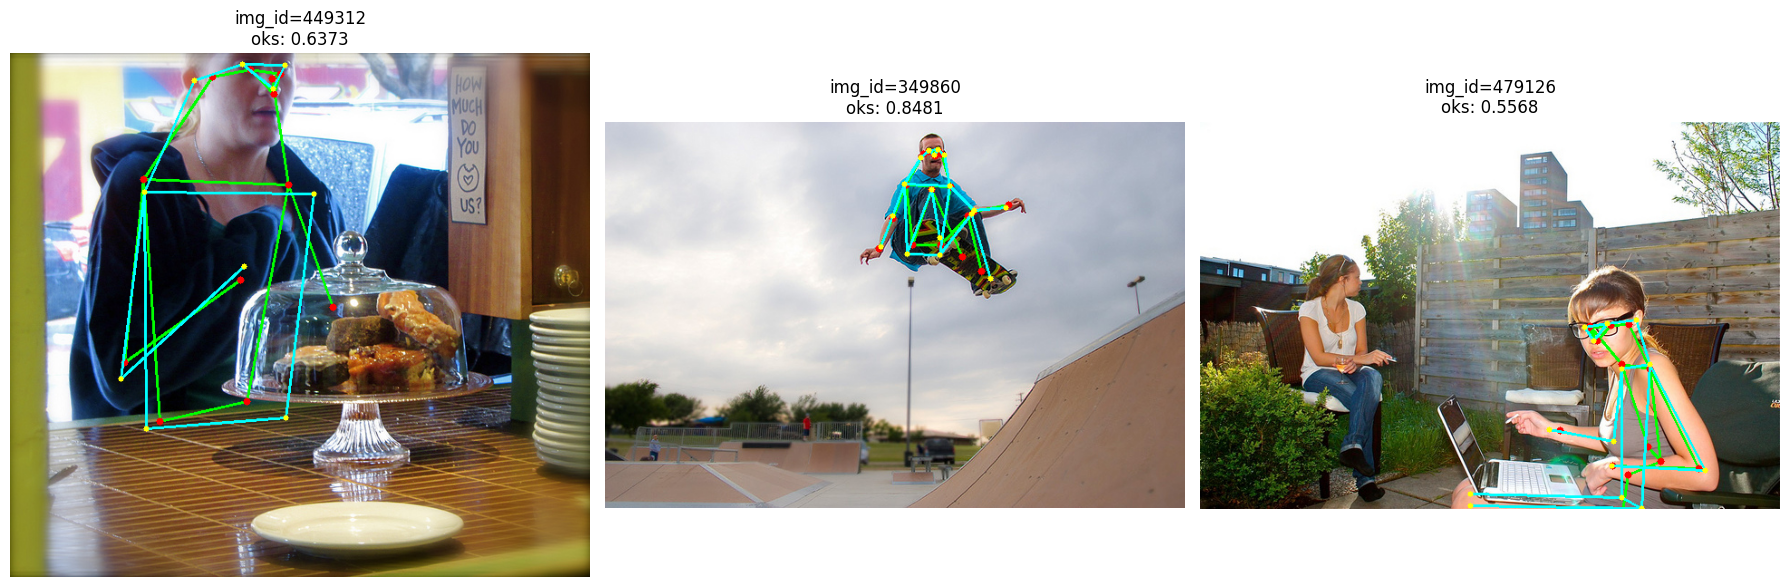

In [45]:
visualize_predictions(cfg, val_preds, mode='random', metric='oks', num_samples=3)

available columns in preds_df: ['image_id', 'category_id', 'keypoints', 'score', 'oks', 'matched_gt_keypoints', 'matched_gt_bbox']
loading annotations into memory...
Done (t=0.28s)
creating index...
index created!


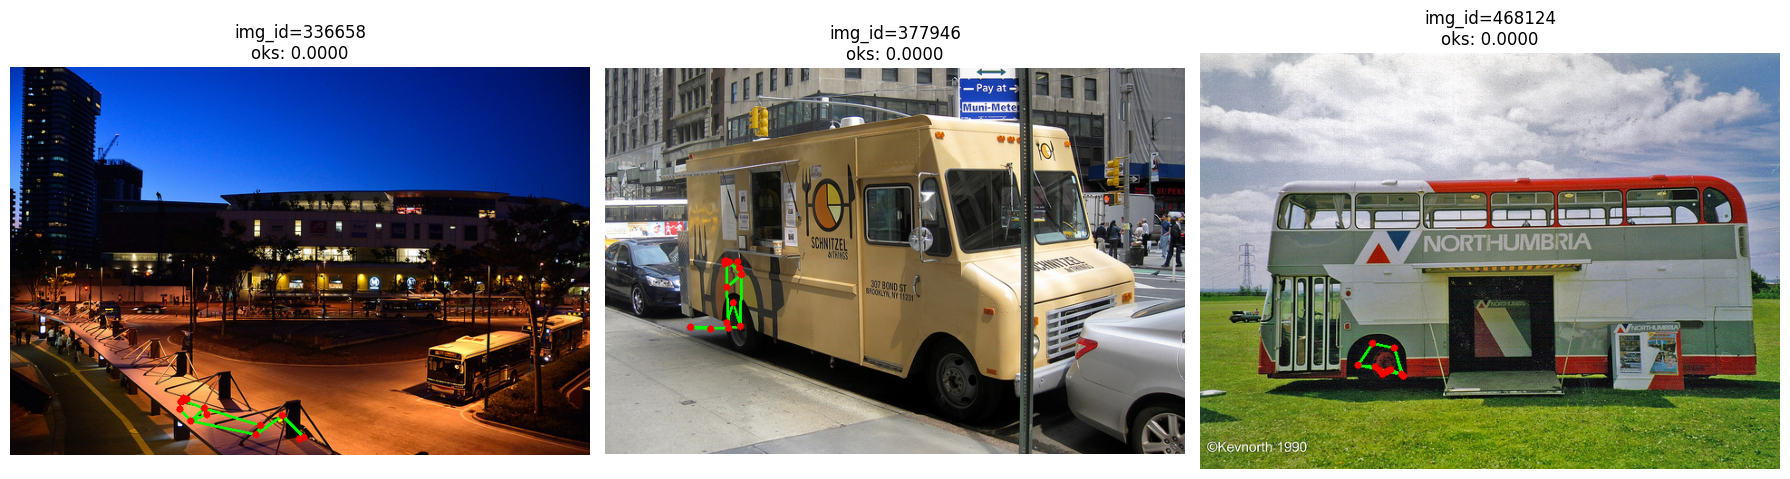

In [46]:
visualize_predictions(cfg, val_preds, mode='worst', metric='oks', num_samples=3)

available columns in preds_df: ['image_id', 'category_id', 'keypoints', 'score', 'oks', 'matched_gt_keypoints', 'matched_gt_bbox']
loading annotations into memory...
Done (t=0.26s)
creating index...
index created!


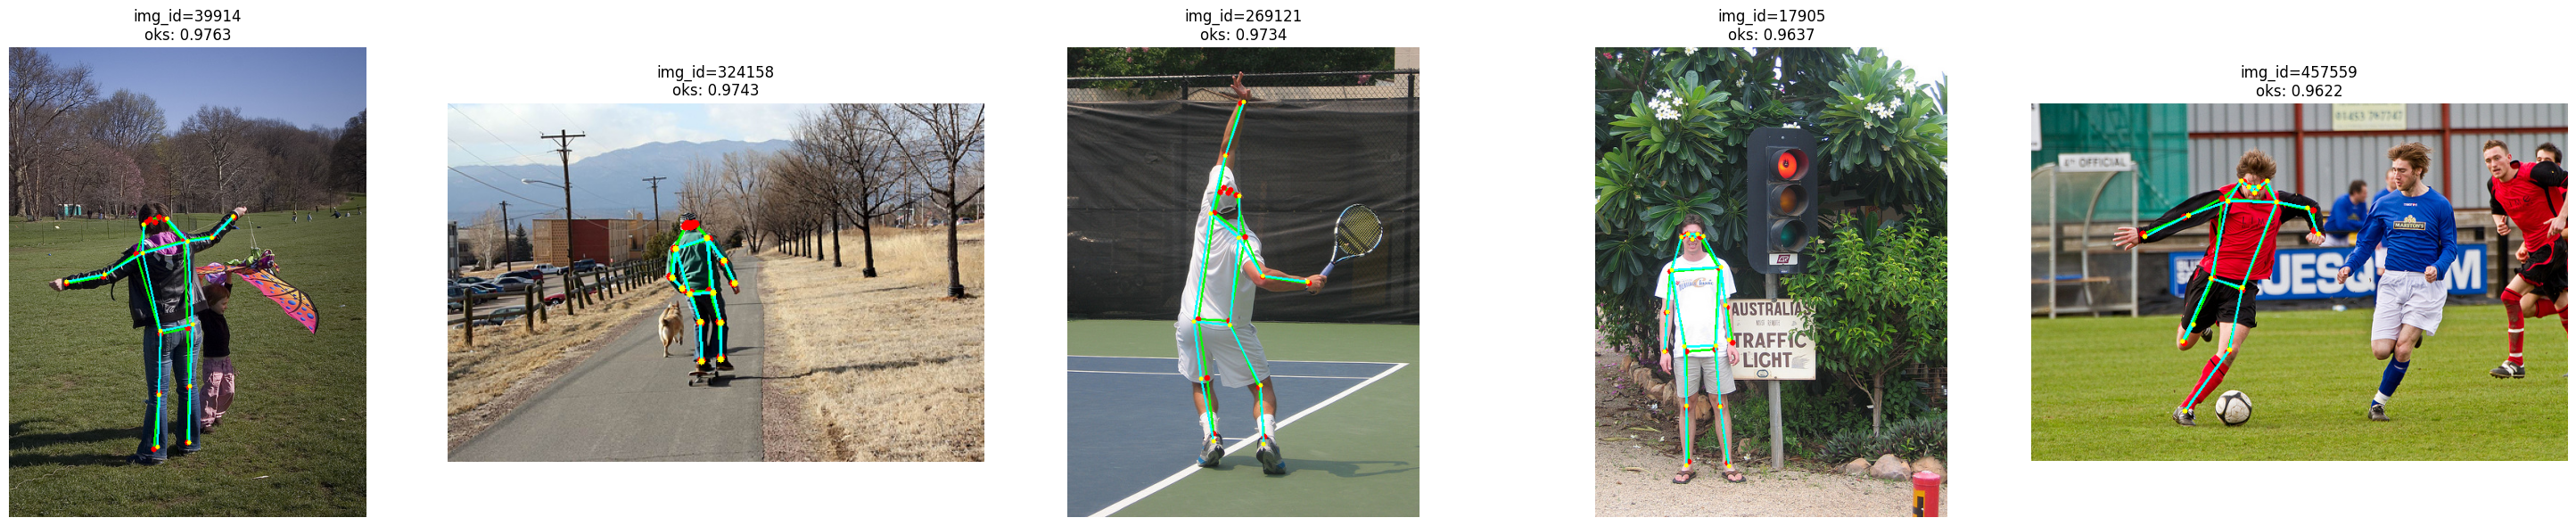

In [47]:
visualize_predictions(cfg, val_preds, mode='best', metric='oks', num_samples=5)